# EDA i podział danych: SMS Spam Collection (Milestone 1)

Plan:
1. dane, typy zmiennych, rozkład klas, jawne braki,
2. duplikaty i bliskie duplikaty, zamrożony podział 70/15/15 (seed 42) bez przecieku,
3. na zbiorze treningowym: ukryte braki, rozkłady i skośność, obserwacje odstające, korelacje, zdolność dyskryminacyjna zmiennych (ANOVA, wariancja, test χ²), reprezentacja worka słów,
4. wnioski: hipotezy dla wariantów przetwarzania P1-P3.

Fakty o zbiorze (liczebności, braki jawne, duplikaty, podział) liczymy na wszystkich rekordach. Wszystko, co uzasadnia wariant przetwarzania, liczymy **tylko na treningu** (walidację używamy raz, w sekcji 13). Test nie wpływa na wybór wariantów.

Notebook zapisuje `data/splits/split_seed42.csv` (+ `.meta.json`) oraz wykresy do `reports/milestone1/`. Podział jest zamrożony: ponowne uruchomienie sprawdza, że wychodzi identyczny, i niczego nie nadpisuje.

Uruchomienie: `uv sync`, potem notebook w PyCharm / `uv run jupyter lab` (komórki po kolei, od góry), albo w całości:
`uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb`

## 0. Konfiguracja

In [1]:
import hashlib
import json
import platform
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from scipy.stats import chi2_contingency
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2, f_classif
from sklearn.model_selection import StratifiedGroupKFold

from smsspam import patterns as P
from smsspam.data import ROOT, SPLIT_DIR, load_config, load_raw

cfg = load_config()
OUT = ROOT / "reports" / "milestone1"
OUT.mkdir(parents=True, exist_ok=True)
LABELS = ("ham", "spam")
# Validated categorical slots 1-2 (light mode); the slides use the same hues.
COLORS = {"ham": "#2a78d6", "spam": "#eb6834"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
# scikit-learn default; B1 uses the same tokenisation.
TOKEN_PATTERN = r"(?u)\b\w\w+\b"

pd.set_option("display.max_colwidth", 140)


def style(ax, grid_axis="x"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=13, length=0)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

## 1. Dane i typy zmiennych

`load_raw()` pobiera archiwum z UCI (tylko raz), sprawdza SHA-256 pliku i zwraca surowy tekst bez żadnego czyszczenia.

In [2]:
df = load_raw()
print({k: cfg["source"][k] for k in ("name", "uci_id", "license", "downloaded", "file_sha256")})
display(df.head())
pd.DataFrame(
    [
        ("id", "identyfikator", "numer linii w pliku źródłowym; nie jest cechą"),
        ("label", "jakościowa binarna", "ham / spam; zmienna objaśniana"),
        ("text", "tekstowa (jakościowa)", "bez przetworzenia do postaci liczbowej nieużyteczna dla modelu"),
    ],
    columns=["zmienna", "typ", "uwagi"],
).set_index("zmienna")

{'name': 'SMS Spam Collection v.1', 'uci_id': 228, 'license': 'CC BY 4.0', 'downloaded': '2026-10-29', 'file_sha256': '7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d'}


,id,label,text
0,0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,1,ham,Ok lar... Joking wif u oni...
2,2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply ...
3,3,ham,U dun say so early hor... U c already then say...
4,4,ham,"Nah I don't think he goes to usf, he lives around here though"


,typ,uwagi
zmienna,,
id,identyfikator,numer linii w pliku źródłowym; nie jest cechą
label,jakościowa binarna,ham / spam; zmienna objaśniana
text,tekstowa (jakościowa),bez przetworzenia do postaci liczbowej nieużyteczna dla modelu


Jedyną zmienną objaśniającą jest surowy tekst. Żeby model mógł go użyć, trzeba go zamienić na liczby. W B1 będzie to worek słów (Bag of Words) z wagami TF-IDF: kolumna na każde słowo ze słownika, wartość zależna od liczby wystąpień. Z tekstu można też wyliczyć zmienne ilościowe (liczba znaków, słów, cyfr), które badamy w sekcjach 8-10.

## 2. Rozkład klas

In [3]:
counts = df.label.value_counts().to_frame("liczba")
counts["udział"] = (counts.liczba / len(df)).round(3)
counts

,liczba,udział
label,,
ham,4827,0.866
spam,747,0.134


Klasy są niezbalansowane (13,4% spamu). Model zawsze odpowiadający „ham” ma accuracy 86,6% i nie wykrywa żadnego spamu, dlatego metryką główną jest F1 dla klasy spam.

## 3. Jawne braki danych

In [4]:
text = df.text
pd.Series({
    "wartości NA (wszystkie kolumny)": df.isna().sum().sum(),
    "puste lub same spacje": (text.str.strip() == "").sum(),
    "spacja na początku/końcu": (text != text.str.strip()).sum(),
    "min. długość [znaki]": text.str.len().min(),
    "maks. długość [znaki]": text.str.len().max(),
}).to_frame("liczba")

,liczba
wartości NA (wszystkie kolumny),0
puste lub same spacje,0
spacja na początku/końcu,187
min. długość [znaki],2
maks. długość [znaki],910


Jawnych braków nie ma: każdy rekord ma etykietę i niepusty tekst. Spacji na brzegach nie przycinamy, bo B1 ma dostać surowy tekst. Braki mogą jednak być ukryte w samej treści wiadomości; wracamy do tego w sekcji 7, już na zbiorze treningowym.

## 4. Dokładne duplikaty

In [5]:
redundant = df.duplicated("text")
display(pd.DataFrame({
    "nadmiarowe kopie": df[redundant].label.value_counts(),
    "% klasy": (100 * df[redundant].label.value_counts() / df.label.value_counts()).round(1),
}))
print("unikalne teksty:", df.text.nunique())
print("teksty z konfliktem etykiet:", (df.groupby("text").label.nunique() > 1).sum())
df.text.value_counts().head(5).to_frame("powtórzenia")

,nadmiarowe kopie,% klasy
label,,
ham,309,6.4
spam,94,12.6


unikalne teksty: 5171
teksty z konfliktem etykiet: 0


,powtórzenia
text,
"Sorry, I'll call later",30
I cant pick the phone right now. Pls send a message,12
Ok...,10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!,4
"Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.",4


- 403 nadmiarowe kopie (7,2%) i żadnego tekstu z dwiema różnymi etykietami.
- Spam powtarza się dwa razy częściej niż ham (12,6% vs 6,4%): te same kampanie wysyłano wielokrotnie.
- Kopia tej samej wiadomości w treningu i w teście oznacza, że model „widział” przykład testowy. Dlatego duplikaty grupujemy przy podziale.

## 5. Bliskie duplikaty

Wiadomości różniące się numerem, kwotą lub jednym słowem też są w praktyce tym samym przykładem. Każdą wiadomość zapisujemy jako wektor zliczeń n-gramów znakowych (fragmentów 3-5 znaków, z wagami TF-IDF) i porównujemy pary miarą cosinusową (1 = identyczne, 0 = nic wspólnego). Pary powyżej progu łączymy, a połączone składowe tworzą grupy.

Wektoryzator widzi wszystkie teksty, ale nie etykiety. To kontrola podziału, a nie cecha modelu.

In [6]:
nd = cfg["near_dup"]
X = TfidfVectorizer(
    analyzer=nd["analyzer"], ngram_range=(nd["ngram_min"], nd["ngram_max"]), sublinear_tf=True
).fit_transform(df.text)
sim = sparse.triu(X @ X.T, k=1).tocoo()
y, texts = df.label.to_numpy(), df.text.to_numpy()


def groups_at(threshold: float) -> np.ndarray:
    keep = sim.data >= threshold
    adj = sparse.coo_matrix((np.ones(keep.sum()), (sim.row[keep], sim.col[keep])), shape=(len(df), len(df)))
    return connected_components(adj, directed=False)[1]


rows = []
for th in (0.95, 0.9, 0.8, 0.7, 0.6, 0.5):
    keep = sim.data >= th
    sizes = np.bincount(g := groups_at(th))
    rows.append({
        "próg": th,
        "pary": keep.sum(),
        "pary nieidentyczne": (texts[sim.row[keep]] != texts[sim.col[keep]]).sum(),
        "pary ham-spam": (y[sim.row[keep]] != y[sim.col[keep]]).sum(),
        "grupy": len(sizes),
        "największa grupa": sizes.max(),
        "rekordy w grupach > 1": (sizes[g] > 1).sum(),
    })
pd.DataFrame(rows).set_index("próg")

,pary,pary nieidentyczne,pary ham-spam,grupy,największa grupa,rekordy w grupach > 1
próg,,,,,,
0.95,1068,84,0,5114,30,777
0.90,1154,170,0,5065,30,852
0.80,1408,424,0,4990,36,954
0.70,1739,755,0,4897,40,1061
0.60,2206,1222,0,4763,45,1218
0.50,2971,1987,0,4475,49,1553


Przy żadnym progu nie ma pary ham-spam, a największa grupa rośnie powoli. Jak wyglądają pary w pasmach wokół progu:

In [7]:
rng = np.random.default_rng(0)
for lo, hi in ((0.7, 0.8), (0.6, 0.7)):
    for lab in LABELS:
        idx = np.flatnonzero((sim.data >= lo) & (sim.data < hi) & (y[sim.row] == lab))
        print(f"--- [{lo}, {hi}) {lab}: {len(idx)} par")
        for i in rng.choice(idx, 3, replace=False):
            print(f"  {sim.data[i]:.2f}  A: {texts[sim.row[i]][:100]}")
            print(f"        B: {texts[sim.col[i]][:100]}")

--- [0.7, 0.8) ham: 192 par
  0.77  A: Sorry, I'll call later
        B: Sorry, I'll call later In meeting.
  0.74  A: Sorry, I'll call later
        B: Sorry, I'll call later  &lt;#&gt; mins
  0.74  A: Sorry, I'll call later
        B: Sorry, I'll call later  &lt;#&gt; mins
--- [0.7, 0.8) spam: 139 par
  0.72  A: Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera f
        B: December only! Had your mobile 11mths+? You are entitled to update to the latest colour camera mobil
  0.71  A: We tried to contact you re your reply to our offer of a Video Handset? 750 anytime networks mins? UN
        B: We tried to call you re your reply to our sms for a video mobile 750 mins UNLIMITED TEXT + free camc
  0.73  A: PRIVATE! Your 2004 Account Statement for 07742676969 shows 786 unredeemed Bonus Points. To claim cal
        B: PRIVATE! Your 2004 Account Statement for 078498****7 shows 786 unredeemed Bonus Points. To claim cal


--- [0.6, 0.7) ham: 267 par
  0.63  A: Sorry, I'll call later
        B: Sorry, I'll call you  later. I am in meeting sir.
  0.61  A: Sorry i'm not free...
        B: Can... I'm free...
  0.62  A: Good morning princess! Happy New Year!
        B: Good morning princess! Have a great day!
--- [0.6, 0.7) spam: 200 par
  0.68  A: Urgent Please call 09066612661 from landline. £5000 cash or a luxury 4* Canary Islands Holiday await
        B: Urgent! Please call 09061213237 from landline. £5000 cash or a luxury 4* Canary Islands Holiday awai
  0.69  A: PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S. I. M. points. Call 08719899230 Ide
        B: PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S.I.M. points. Call 08718738001 Ident
  0.67  A: Dear 0776xxxxxxx U've been invited to XCHAT. This is our final attempt to contact u! Txt CHAT to 866
        B: Hi there, 2nights ur lucky night! Uve been invited 2 XCHAT, the Uks wildest chat! Txt CHAT to 86688 


- W paśmie 0,7-0,8 spam to wciąż ten sam szablon z innym numerem lub kwotą. To bliskie duplikaty.
- Poniżej 0,7 zaczynają się łączyć hamy, które dzielą tylko wspólną frazę („Sorry i'm not free...” / „Can... I'm free...”, „Good morning princess! Happy New Year!” / „…Have a great day!”).

**Decyzja:** próg 0,7. Zostawiamy wszystkie rekordy (naturalny rozkład klas w teście), a każda grupa trafia w całości do jednej części podziału.

In [8]:
df["dup_group"] = groups_at(nd["threshold"])
df.dup_group.nunique()

4897

## 6. Podział 70/15/15

Brak oficjalnego podziału, więc `StratifiedGroupKFold` z 20 foldami (po ~5%): 3 foldy to test, 3 walidacja, 14 trening. Losowanie ze stratyfikacją po etykiecie (te same proporcje klas w każdej części), z grupami z sekcji 5, seed 42.

In [9]:
sc = cfg["split"]
n_test, n_val = round(sc["test"] * sc["n_folds"]), round(sc["val"] * sc["n_folds"])
sgkf = StratifiedGroupKFold(n_splits=sc["n_folds"], shuffle=True, random_state=sc["seed"])
fold = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(np.zeros(len(df)), df.label, df.dup_group)):
    fold[idx] = k
df["split"] = np.where(fold < n_test, "test", np.where(fold < n_test + n_val, "val", "train"))

table = df.groupby(["split", "label"]).size().unstack().reindex(["train", "val", "test"])
table["razem"] = table.sum(axis=1)
table["% spam"] = (100 * table.spam / table.razem).round(1)
table

label,ham,spam,razem,% spam
split,,,,
train,3378,522,3900,13.4
val,725,112,837,13.4
test,724,113,837,13.5


**Kontrola przecieku.** Żadna grupa ani identyczny tekst nie może być w dwóch częściach. Dla każdego rekordu z walidacji i testu liczymy też najwyższe podobieństwo do dowolnego rekordu treningowego.

In [10]:
assert (df.groupby("dup_group").split.nunique() == 1).all()
assert (df.groupby("text").split.nunique() == 1).all()

train_idx = np.flatnonzero(df.split == "train")
max_sim = (X @ X[train_idx].T).max(axis=1).toarray().ravel()
max_sim[train_idx] = np.nan
df["max_sim_to_train"] = max_sim
held_out = df[df.split != "train"]
assert (held_out.max_sim_to_train < nd["threshold"]).all()

pd.DataFrame({
    f"cos >= {th}": held_out[held_out.max_sim_to_train >= th].groupby(["split", "label"]).size()
    for th in (0.5, 0.6)
}).fillna(0).astype(int)

cos >= 0.5  cos >= 0.6
split label                        
test  ham            79          25
      spam           41          24
val   ham            73          17
      spam           25          16

In [11]:
test = df[df.split == "test"]
group_size = df.dup_group.map(df.dup_group.value_counts())
print("unikalne teksty w teście:", test.text.nunique(), "z", len(test))
print("rekordy testu w grupach > 1:", test[group_size[test.index] > 1].label.value_counts().to_dict())
print("największe grupy:")
df.groupby("dup_group").agg(n=("id", "size"), label=("label", "first"), split=("split", "first"), text=("text", "first")).nlargest(5, "n")

unikalne teksty w teście: 781 z 837
rekordy testu w grupach > 1: {'ham': 92, 'spam': 65}
największe grupy:


,n,label,split,text
dup_group,,,,
57,40,ham,val,"Sorry, I'll call later in meeting."
291,12,ham,test,I cant pick the phone right now. Pls send a message
1196,12,ham,test,Ok...
269,11,ham,test,Thanx...
252,10,spam,train,We tried to contact you re your reply to our offer of a Video Handset? 750 anytime networks mins? UNLIMITED TEXT? Camcorder? Reply or ca...


- Proporcja spamu w każdej części wynosi 13,4-13,5%.
- Żaden rekord z walidacji ani testu nie ma podobieństwa ≥ 0,7 do treningu.
- Zostaje pasmo 0,5-0,7 (w teście 41 spamów): te same kampanie w innej wersji. To realistyczne, ale może zawyżać wynik, dlatego pokażemy też wynik na podzbiorze testu z podobieństwem < 0,5.
- 65 ze 113 spamów testu należy do grup duplikatów wewnątrz testu, więc te kampanie liczą się podwójnie. Dlatego raportujemy też wynik na teście po deduplikacji.

Zapis zamrożonego podziału. Jeśli plik już istnieje, sprawdzamy tylko, że wyszedł identyczny:

In [12]:
df["text_sha1"] = df.text.map(lambda t: hashlib.sha1(t.encode()).hexdigest())
split = df[["id", "label", "split", "dup_group", "text_sha1"]]
split_path = SPLIT_DIR / f"split_seed{sc['seed']}.csv"
if split_path.exists():
    pd.testing.assert_frame_equal(split, pd.read_csv(split_path), check_dtype=False)
    print("podział zgodny z zamrożonym:", split_path.relative_to(ROOT))
else:
    SPLIT_DIR.mkdir(parents=True, exist_ok=True)
    split.to_csv(split_path, index=False)
    print("zapisano:", split_path.relative_to(ROOT))

sizes = df.dup_group.value_counts()
meta = {
    "source": cfg["source"],
    "split_config": sc,
    "near_dup_config": nd,
    "n_records": len(df),
    "counts": df.groupby(["split", "label"]).size().unstack().to_dict(orient="index"),
    "spam_share": df.groupby("split").label.apply(lambda s: round((s == "spam").mean(), 4)).to_dict(),
    "n_groups": int(df.dup_group.nunique()),
    "records_in_multi_groups": int((df.dup_group.map(sizes) > 1).sum()),
    "largest_group": int(sizes.max()),
    "held_out_max_sim_to_train": {
        "median": round(float(held_out.max_sim_to_train.median()), 4),
        "counts": {
            f">={th}": {s: int(((df.max_sim_to_train >= th) & (df.split == s)).sum()) for s in ("val", "test")}
            for th in (0.5, 0.6, 0.7)
        },
    },
    "environment": {
        "python": platform.python_version(),
        **{pkg: version(pkg) for pkg in ("numpy", "pandas", "scipy", "scikit-learn")},
    },
}
meta_path = SPLIT_DIR / f"split_seed{sc['seed']}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False) + "\n")
print("zapisano:", meta_path.relative_to(ROOT))

podział zgodny z zamrożonym: data/splits/split_seed42.csv
zapisano: data/splits/split_seed42.meta.json


## 7. Ukryte braki i błędy zapisu (train)

Od tego miejsca pracujemy tylko na zbiorze treningowym.

Jawnych braków nie było, ale część wiadomości zawiera `&lt;#&gt;`, czyli zakodowane `<#>`. To znacznik, którym jedno ze źródeł zbioru (korpus NUS, z którego pochodzi większość hamów) zastąpiło liczby przy anonimizacji. Wartość liczby została więc usunięta: jest to brak danych, tylko zapisany w tekście.

In [13]:
train, val = df[df.split == "train"], df[df.split == "val"]
placeholder = train.text.str.contains("&lt;#&gt;", regex=False)
has_digit = train.text.str.contains(r"\d")
display(pd.DataFrame({
    "% z &lt;#&gt;": 100 * placeholder.groupby(train.label).mean(),
    "% z cyfrą": 100 * has_digit.groupby(train.label).mean(),
}).round(1))
train[placeholder][["id", "label", "text"]].head(5)

,% z &lt;#&gt;,% z cyfrą
label,,
ham,4.6,15.7
spam,0.0,94.8


,id,label,text
44,44,ham,Great! I hope you like your man well endowed. I am &lt;#&gt; inches...
51,51,ham,"A gram usually runs like &lt;#&gt; , a half eighth is smarter though and gets you almost a whole second gram for &lt;#&gt;"
78,78,ham,Does not operate after &lt;#&gt; or what
178,178,ham,"Turns out my friends are staying for the whole show and won't be back til ~ &lt;#&gt; , so feel free to go ahead and smoke that $ &lt;#&..."
200,200,ham,"Found it, ENC &lt;#&gt; , where you at?"


- Znacznik występuje **wyłącznie w hamie**. Brak nie jest przypadkowy: zależy od źródła danych i od tego, że w miejscu znacznika była liczba (wartość, której brakuje). To brak danych z jednego źródła, powiązany z etykietą.
- Skutek dla modelu: tokenizator B1 zrobi ze znacznika tokeny `lt` i `gt`, które będą „wskazywać” ham (sekcja 12). Model nauczy się wtedy rozpoznawać źródło danych zamiast treści.
- Możliwe postępowanie: zostawić (B1), usunąć znacznik albo zastąpić go tym samym symbolem co inne liczby (uzupełnienie braku kategorią „tu była liczba”).

Drugi problem jakości to błędy zapisu: część wiadomości ma nieprzekodowane znaki z Windows-1252 (np. `\x92` zamiast apostrofu).

In [14]:
c1 = train.text.str.contains(P.C1_CONTROL)
print("wiadomości z błędnym znakiem:", c1.groupby(train.label).sum().to_dict())
train[c1].text.head(3).map(repr).to_frame("tekst (repr)")

wiadomości z błędnym znakiem: {'ham': 26, 'spam': 2}


,tekst (repr)
18,'Fine if that\x92s the way u feel. That\x92s the way its gota b'
793,'Y?WHERE U AT DOGBREATH? ITS JUST SOUNDING LIKE JAN C THAT\x92S AL!!!!!!!!!'
820,"'""BOO BABE! U ENJOYIN YOURJOB? U SEEMED 2 B GETTIN ON WELL HUNNY!HOPE URE OK?TAKE CARE & I\x92LLSPEAK 2U SOONLOTS OF LOVEME XXXX.""'"


Błędów zapisu jest mało (poniżej 1% w każdej klasie) i występują w obu klasach. Nie usuwamy tych wiadomości; poprawa kodowania mogłaby być ewentualnym wariantem przetwarzania, ale ma znikomy zasięg.

## 8. Zmienne ilościowe wyliczone z tekstu (train)

Z każdej wiadomości liczymy kilka zmiennych ilościowych: liczbę znaków, słów, cyfr i znaków interpunkcyjnych (zliczenia) oraz udział wielkich liter wśród liter (zmienna ilorazowa).

In [15]:
def derived(text: pd.Series) -> pd.DataFrame:
    letters = text.str.count(r"[A-Za-z]")
    return pd.DataFrame({
        "znaki": text.str.len(),
        "słowa": text.str.split().str.len(),
        "cyfry": text.str.count(r"\d"),
        "interpunkcja": text.str.count(r"[^\w\s]"),
        "wielkie litery [%]": (100 * text.str.count(r"[A-Z]") / letters.where(letters > 0)).fillna(0),
    })


feats = derived(train.text)
feats.groupby(train.label).agg(["mean", "median", "std"]).T.round(1)

label                       ham   spam
znaki              mean    72.4  139.4
                   median  53.0  149.0
                   std     59.9   28.0
słowa              mean    14.5   24.1
                   median  11.0   25.0
                   std     11.7    5.6
cyfry              mean     0.3   16.1
                   median   0.0   16.0
                   std      1.2    8.8
interpunkcja       mean     4.0    6.1
                   median   3.0    6.0
                   std      4.9    3.6
wielkie litery [%] mean     7.8   16.8
                   median   4.5   14.8
                   std     15.1   13.3

**Skośność.** Liczymy trzy współczynniki skośności: A_d = (μ − d)/s (z dominantą d), A_m = 3(μ − m)/s (z medianą m) i A_Q = (Q1 + Q3 − 2m)/(Q3 − Q1) (z kwartyli). Wartość 0 oznacza rozkład symetryczny, dodatnia prawostronną skośność, ujemna lewostronną. Sprawdzamy też, co daje logarytmowanie, które zwykle usuwa prawostronną skośność danych dodatnich.

In [16]:
def skewness(x: pd.Series) -> dict:
    mu, m, s = x.mean(), x.median(), x.std()
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    return {
        "A_d (dominanta)": (mu - x.mode().iloc[0]) / s,
        "A_m (mediana)": 3 * (mu - m) / s,
        "A_Q (kwartyle)": (q1 + q3 - 2 * m) / (q3 - q1),
    }


rows = {}
for lab in LABELS:
    x = feats.znaki[train.label == lab]
    rows[(lab, "znaki")] = skewness(x)
    rows[(lab, "log10(znaki)")] = skewness(np.log10(x))
pd.DataFrame(rows).T.round(2)

A_d (dominanta)  A_m (mediana)  A_Q (kwartyle)
ham  znaki                    0.68           0.97            0.37
     log10(znaki)             0.79           0.25            0.13
spam znaki                   -0.66          -1.03           -0.30
     log10(znaki)            -0.55          -1.03           -0.34

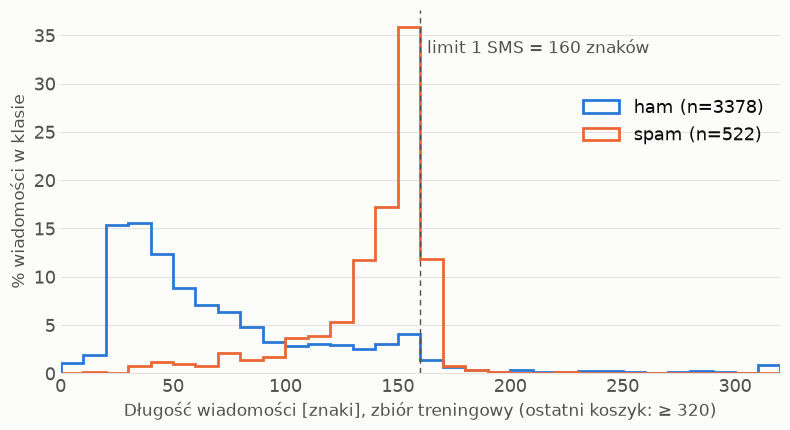

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.4), facecolor=SURFACE)
style(ax, grid_axis="y")
bins = np.arange(0, 330, 10)
clipped = feats.znaki.clip(upper=bins[-1] - 1)
for lab in LABELS:
    c = clipped[train.label == lab]
    ax.hist(c, bins=bins, weights=np.full(len(c), 100 / len(c)), histtype="step", linewidth=2,
            color=COLORS[lab], label=f"{lab} (n={len(c)})")
ax.axvline(160, color=INK_2, linewidth=1, linestyle=(0, (4, 3)))
ax.text(163, ax.get_ylim()[1] * 0.92, "limit 1 SMS = 160 znaków", color=INK_2, fontsize=12, va="top")
ax.set_xlabel("Długość wiadomości [znaki], zbiór treningowy (ostatni koszyk: ≥ 320)", color=INK_2, fontsize=12.5)
ax.set_ylabel("% wiadomości w klasie", color=INK_2, fontsize=12.5)
ax.set_xlim(0, bins[-1])
ax.legend(frameon=False, fontsize=13, labelcolor=INK, loc="upper right", bbox_to_anchor=(1, 0.8))
fig.tight_layout()
fig.savefig(OUT / "fig_length.png", dpi=200)

- Ham ma rozkład prawostronnie skośny (wszystkie współczynniki dodatnie): dużo krótkich wiadomości i długi ogon. Po logarytmowaniu A_m spada z 0,97 do 0,25, a A_Q z 0,37 do 0,13.
- Spam ma rozkład lewostronnie skośny (wszystkie ujemne): wiadomości „dobijają” do limitu jednego SMS-a (160 znaków), a ogon to krótsze wiadomości. Logarytmowanie usuwa prawostronną skośność, więc tu nie pomaga: A_m się nie zmienia.
- Różne współczynniki oceniają ten sam rozkład inaczej. A_d zależy od jednej wartości (dominanty) i po logarytmowaniu hamu nawet rośnie, ale znak wszystkich współczynników się zgadza.
- Długość dobrze odróżnia klasy (mediana 149 vs 53 znaki). B1 nie widzi jej wprost; gdyby dodać ją jako cechę, warto ją zlogarytmować (dla hamu) i znormalizować na podstawie samego treningu.

## 9. Obserwacje odstające (train)

Wykres pudełkowy pokazuje medianę, kwartyle Q1 i Q3 oraz wąsy do ±1,5 IQR (rozstępu międzykwartylowego). Punkty poza wąsami to obserwacje odstające według tej reguły.

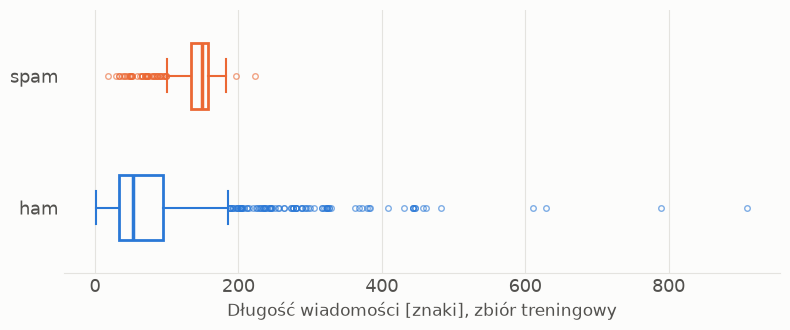

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.4), facecolor=SURFACE)
style(ax)
bp = ax.boxplot([feats.znaki[train.label == lab] for lab in LABELS], orientation="horizontal", widths=0.5,
                patch_artist=True, tick_labels=LABELS, whis=1.5)
for i, lab in enumerate(LABELS):
    color = COLORS[lab]
    bp["boxes"][i].set(facecolor=SURFACE, edgecolor=color, linewidth=2)
    bp["medians"][i].set(color=color, linewidth=2.5)
    for part in ("whiskers", "caps"):
        for line in bp[part][2 * i:2 * i + 2]:
            line.set(color=color, linewidth=1.5)
    bp["fliers"][i].set(marker="o", markersize=4, markerfacecolor="none", markeredgecolor=color, alpha=0.6)
ax.set_xlabel("Długość wiadomości [znaki], zbiór treningowy", color=INK_2, fontsize=12.5)
fig.tight_layout()
fig.savefig(OUT / "fig_boxplot.png", dpi=200)

In [19]:
def iqr_outliers(x: pd.Series) -> pd.Series:
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    return (x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))


outliers = pd.concat([iqr_outliers(feats.znaki[train.label == lab]) for lab in LABELS])
display(pd.DataFrame({
    "odstające (≥ 1,5 IQR)": outliers.groupby(train.label).sum(),
    "% klasy": (100 * outliers.groupby(train.label).mean()).round(1),
}))
view = train.assign(znaki=feats.znaki, text=train.text.str.slice(0, 110))
display(view.nlargest(3, "znaki")[["label", "znaki", "text"]])
view[train.label == "spam"].nsmallest(3, "znaki")[["label", "znaki", "text"]]

,"odstające (≥ 1,5 IQR)",% klasy
label,,
ham,93,2.8
spam,49,9.4


,label,znaki,text
1085,ham,910,For me the love should start with attraction.i should feel that I need her every time around me.she should be
1863,ham,790,"The last thing i ever wanted to do was hurt you. And i didn't think it would have. You'd laugh, be embarassed,"
2434,ham,629,"Indians r poor but India is not a poor country. Says one of the swiss bank directors. He says that "" &lt;#&gt;"


,label,znaki,text
3981,spam,18,ringtoneking 84484
2079,spam,30,85233 FREE>Ringtone!Reply REAL
1777,spam,33,Call FREEPHONE 0800 542 0578 now!


- Reguła 1,5 IQR oznacza jako odstające długie, wielozdaniowe hamy oraz głównie krótkie spamy. To prawdziwe wiadomości, a nie błędy pomiaru czy wprowadzania danych, więc **ich nie usuwamy**. Usuwać należy tylko obserwacje z wyraźną przyczyną zewnętrzną.
- W spamie rozstęp międzykwartylowy jest wąski (większość wiadomości ma 134-157 znaków), więc reguła oznacza jako odstające wszystkie krótsze spamy. To skutek skośności rozkładu, a nie anomalia.
- Kryterium Chauveneta nie ma tu zastosowania: zakłada rozkład normalny i pojedynczą podejrzaną obserwację, a tu mamy rozkłady skośne i wiele obserwacji poza wąsami.

## 10. Korelacje i zdolność dyskryminacyjna zmiennych ilościowych (train)

Najpierw korelacja między zmiennymi: silnie skorelowane zmienne opisują w praktyce to samo zjawisko.

In [20]:
feats.corr().round(2)

,znaki,słowa,cyfry,interpunkcja,wielkie litery [%]
znaki,1.00,0.97,0.38,0.65,0.07
słowa,0.97,1.00,0.29,0.61,0.05
cyfry,0.38,0.29,1.00,0.20,0.22
interpunkcja,0.65,0.61,0.20,1.00,0.06
wielkie litery [%],0.07,0.05,0.22,0.06,1.00


Następnie dwa sposoby oceny, czy zmienna odróżnia klasy:
- **iloraz wariancji**: po normalizacji min-max liczymy sumę wariancji wewnątrz klas podzieloną przez wariancję w całym zbiorze. Mniejsza wartość oznacza mały rozrzut w klasach przy dużym rozrzucie ogólnym, czyli lepszą zmienną (przy braku związku z klasą wynik jest bliski 2).
- **test ANOVA**: hipoteza zerowa mówi, że średnia zmiennej jest taka sama w obu klasach. Statystyka F to stosunek wariancji między klasami do wariancji wewnątrz klas; małe p pozwala odrzucić hipotezę zerową.

In [21]:
norm = (feats - feats.min()) / (feats.max() - feats.min())
var_class = norm.groupby(train.label).var()
F, p = f_classif(feats, train.label)
pd.DataFrame({
    "wariancja (całość)": norm.var(),
    "wariancja ham": var_class.loc["ham"],
    "wariancja spam": var_class.loc["spam"],
    "Σ w klasach / całość": var_class.sum() / norm.var(),
    "F (ANOVA)": F,
    "p": p,
}).sort_values("Σ w klasach / całość").style.format({"p": "{:.1e}"}, precision=3)

,wariancja (całość),wariancja ham,wariancja spam,Σ w klasach / całość,F (ANOVA),p
znaki,0.005,0.004,0.001,1.172,632.078,2.2e-129
słowa,0.005,0.005,0.001,1.264,337.464,2.4e-72
interpunkcja,0.001,0.001,0.001,1.597,89.692,4.7e-21
wielkie litery [%],0.023,0.023,0.018,1.754,162.560,1.7e-36
cyfry,0.024,0.001,0.046,1.950,9754.229,0.0e+00


- Liczba znaków i słów są silnie skorelowane (0,97), więc niosą prawie tę samą informację.
- Oba kryteria dają **różne rankingi**. Według ANOVA zdecydowanie najlepsza jest **liczba cyfr** (F ≈ 9750, kilkanaście razy więcej niż długość), a według ilorazu wariancji ta sama zmienna jest najgorsza.
- Powód: iloraz sumuje wariancje klas bez wag. W hamie cyfr prawie nie ma (wariancja bliska zeru), ale w małej klasie spam ich liczba bardzo się waha, a wariancja całości jest zdominowana przez liczny ham. ANOVA waży wariancję wewnątrzklasową liczebnością klas. Przy niezbalansowanych klasach iloraz wariancji bez wag łatwo wprowadza w błąd.
- Normalizacja min-max jest wrażliwa na obserwacje odstające: jedna wiadomość z 910 znakami ściska resztę wartości blisko zera. Iloraz wariancji od tego nie zależy, bo nie zmienia się przy przeskalowaniu, ale gdyby te zmienne trafiły do modelu, parametry normalizacji trzeba wyznaczyć wyłącznie na treningu.

Cyfry niosą sygnał spamu, ale B1 widzi je tylko jako pojedyncze tokeny (np. konkretny numer telefonu). Sekcje 11-13 sprawdzają, co z tego wynika.

## 11. Znaczniki w tekście i test χ² (train)

Zamieniamy obecność wybranych wzorców w zmienne binarne (jest / nie ma), np. „wiadomość zawiera numer telefonu”. Wzorce są w `smsspam/patterns.py` i posłużą też w wariantach P. Dla każdego znacznika robimy test χ² niezależności na tabeli 2×2 (znacznik × klasa): hipoteza zerowa mówi, że obecność znacznika nie zależy od klasy.

In [22]:
MARKERS = {
    "Numer telefonu (>= 8 cyfr)": P.PHONE,
    "Kod krótki (5-6 cyfr)": P.SHORTCODE,
    "Kwota (£, $, 150p)": P.MONEY,
    "URL / domena": P.URL,
    "Encja HTML (&lt; &gt; &amp;)": P.HTML_ENTITY,
    "Emotikona :) ;-)": P.EMOTICON,
    "Wielokropek / !!! / ???": P.REPEATED_PUNCT,
    "Powtórzona litera (sooo)": P.REPEATED_LETTER,
    "Znak C1 z cp1252 (\\x92)": P.C1_CONTROL,
}
hits = pd.DataFrame({name: train.text.map(lambda t, pat=pat: pat.search(t) is not None) for name, pat in MARKERS.items()})

rows = {}
for name in hits:
    stat, p, dof, _ = chi2_contingency(pd.crosstab(hits[name], train.label), correction=False)
    rows[name] = {
        "% ham": 100 * hits[name][train.label == "ham"].mean(),
        "% spam": 100 * hits[name][train.label == "spam"].mean(),
        "χ²": stat,
        "p": p,
    }
prev = pd.DataFrame(rows).T
prev.sort_values("χ²", ascending=False).style.format({"p": "{:.1e}"}, precision=1).format_index(escape="html")

,% ham,% spam,χ²,p
Numer telefonu (>= 8 cyfr),0.1,61.5,2246.5,0.0e+00
"Kwota (£, $, 150p)",0.3,51.7,1786.5,0.0e+00
Kod krótki (5-6 cyfr),0.0,34.1,1207.0,1.9e-264
URL / domena,0.3,18.2,546.3,8.1e-121
Wielokropek / !!! / ???,15.7,1.7,74.0,7.7e-18
Encja HTML (&lt; &gt; &amp;),6.7,0.0,37.2,1.0e-09
Emotikona :) ;-),3.3,0.0,17.8,2.4e-05
Znak C1 z cp1252 (\x92),0.8,0.4,0.9,3.3e-01
Powtórzona litera (sooo),2.3,2.9,0.6,4.3e-01


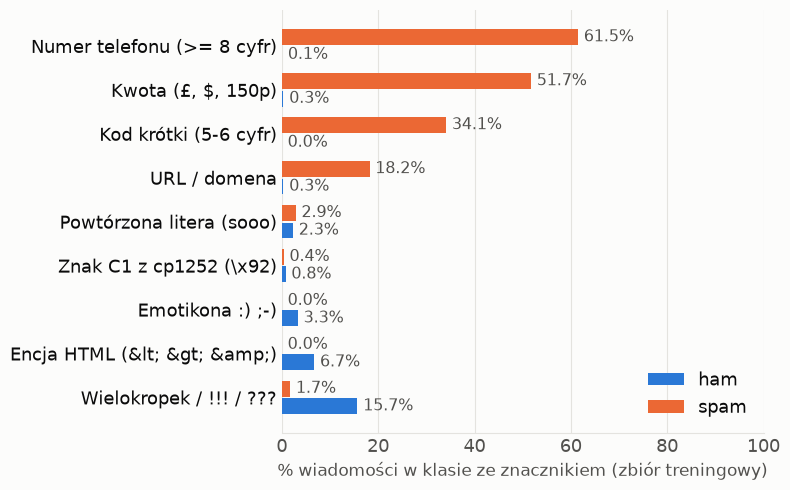

In [23]:
plot = prev.assign(diff=prev["% spam"] - prev["% ham"]).sort_values("diff")
pos, h = np.arange(len(plot)), 0.36
fig, ax = plt.subplots(figsize=(8, 5), facecolor=SURFACE)
style(ax)
for offset, lab in ((h / 2 + 0.02, "spam"), (-h / 2 - 0.02, "ham")):
    vals = plot[f"% {lab}"].to_numpy()
    ax.barh(pos + offset, vals, height=h, color=COLORS[lab], label=lab)
    for yi, v in zip(pos + offset, vals):
        ax.text(v + 1.2, yi, f"{v:.1f}%", va="center", fontsize=11.5, color=INK_2)
ax.set_yticks(pos, plot.index, color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("% wiadomości w klasie ze znacznikiem (zbiór treningowy)", color=INK_2, fontsize=12.5)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], frameon=False, fontsize=13, loc="lower right", labelcolor=INK)
fig.tight_layout()
fig.savefig(OUT / "fig_markers.png", dpi=200)

Co wzorce faktycznie łapią w spamie:

In [24]:
sample = train[train.label == "spam"].head(8)
found = {
    name: sample.text.map(lambda t, pat=pat: ", ".join(m.group(0) for m in pat.finditer(t)))
    for name, pat in {"PHONE": P.PHONE, "SHORTCODE": P.SHORTCODE, "MONEY": P.MONEY, "URL": P.URL}.items()
}
pd.DataFrame({"text": sample.text.str.slice(0, 70), **found}).set_index(sample.id)

,text,PHONE,SHORTCODE,MONEY,URL
id,,,,,
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Te,08452810075,87121,,
8,WINNER!! As a valued network customer you have been selected to receiv,09061701461,,£900,
9,Had your mobile 11 months or more? U R entitled to Update to the lates,08002986030,,,
15,"XXXMobileMovieClub: To use your credit, click the WAP link in the next",,,,"http://wap., xxxmobilemovieclub.com?n=QJKGIGHJJGCBL"
42,07732584351 - Rodger Burns - MSG = We tried to call you re your reply,"07732584351, 08000930705",,,
65,"As a valued customer, I am pleased to advise you that following recent",09066364589,,£1500,
93,Please call our customer service representative on 0800 169 6031 betwe,0800 169 6031,,"£1000, £5000",
95,Your free ringtone is waiting to be collected. Simply text the passwor,,85069,,


- Numer telefonu, kwota, kod krótki i URL występują niemal wyłącznie w spamie; test χ² zdecydowanie odrzuca niezależność.
- Encje HTML (znacznik z sekcji 7), emotikony i wielokropki są typowe dla hamu, ale B1 zobaczy z nich tylko encje (jako `lt`/`gt`), bo jego tokenizator pomija interpunkcję.
- Powtórzone litery („sooo”) i błędne znaki są rzadkie, a ich związek z klasą jest słaby (duże p).

## 12. Reprezentacja worka słów (train)

Tak tekst zobaczy B1: słownik budowany na treningu, kolumna na każdy token, tokeny to ciągi co najmniej 2 znaków alfanumerycznych (`\b\w\w+\b`), bez interpunkcji. Tu liczymy samo występowanie tokenu w dokumencie (0/1).

In [25]:
bow = CountVectorizer(token_pattern=TOKEN_PATTERN, binary=True)
Xb = bow.fit_transform(train.text)
vocab = bow.get_feature_names_out()
doc_freq = np.asarray(Xb.sum(axis=0)).ravel()
is_long_number = np.array([t.isdigit() and len(t) >= 8 for t in vocab])
pd.Series({
    "dokumenty (train)": Xb.shape[0],
    "wymiar BoW (tokeny w słowniku)": Xb.shape[1],
    "tokeny występujące w 1 dokumencie": (doc_freq == 1).sum(),
    "długie liczby (>= 8 cyfr)": is_long_number.sum(),
    "długie liczby w <= 2 dokumentach": (is_long_number & (doc_freq <= 2)).sum(),
}).to_frame("liczba")

,liczba
dokumenty (train),3900
wymiar BoW (tokeny w słowniku),7171
tokeny występujące w 1 dokumencie,3778
długie liczby (>= 8 cyfr),188
długie liczby w <= 2 dokumentach,172


- Wymiar reprezentacji (liczba kolumn) jest większy niż liczba dokumentów, a macierz jest prawie cała z zer.
- Ponad połowa tokenów (3778 z 7171) występuje w jednym dokumencie. Taka kolumna ma wariancję bliską zeru i niesie znikomą informację.
- Długie liczby (numery telefonów) to w 91% kolumny obecne w najwyżej dwóch dokumentach: każdy numer to osobna, prawie stała cecha. Tymczasem łączna liczba cyfr to najsilniejsza zmienna ilościowa z sekcji 10.

**Które tokeny najbardziej zależą od klasy?** Test χ² na zliczeniach występowania tokenu w dokumentach każdej klasy.

In [26]:
stat, p = chi2(Xb, train.label)
is_spam = (train.label == "spam").to_numpy()
tok = pd.DataFrame({
    "token": vocab,
    "dok. spam": np.asarray(Xb[is_spam].sum(axis=0)).ravel(),
    "dok. ham": np.asarray(Xb[~is_spam].sum(axis=0)).ravel(),
    "χ²": stat.round(1),
})
tok["klasa"] = np.where(tok["dok. spam"] / is_spam.sum() > tok["dok. ham"] / (~is_spam).sum(), "spam", "ham")
pd.concat({
    lab: tok[tok.klasa == lab].nlargest(12, "χ²").drop(columns="klasa").reset_index(drop=True)
    for lab in LABELS
}, axis=1)

ham                             spam                          
   token dok. spam dok. ham    χ²   token dok. spam dok. ham     χ²
0     my        10      414  44.5    call       245      134  859.0
1     me        17      464  40.3     txt       104        8  610.2
2     it        16      418  35.2    free       128       41  566.8
3    but         5      289  34.6   claim        70        0  453.0
4   that        13      348  29.8     www        71        2  443.0
5     gt         0      177  27.4  mobile        76       10  417.1
6     lt         0      175  27.0    stop        71       18  338.4
7    how         4      206  23.9   prize        52        0  336.5
8   come         1      152  21.4      uk        50        1  315.3
9     ok         3      177  21.3    150p        48        0  310.6
10    he         0      126  19.5   reply        67       22  294.1
11    ll         3      152  17.5      or       140      157  291.9

- Po stronie spamu: wezwania i słowa z ofert („call”, „txt”, „free”, „claim”, „prize”, „reply”, „stop”), fragmenty adresów („www”, „uk”) i kwota jako token („150p”).
- Po stronie hamu dominują słowa codziennej rozmowy („my”, „me”, „it”, „but”), a zaraz za nimi są `gt` i `lt`, czyli resztki znacznika z sekcji 7 (0 wystąpień w spamie). Model B1 potraktuje artefakt anonimizacji jako jedną z mocniejszych wskazówek hamu.

## 13. Sprawdzenie na walidacji: czy numery z nowych wiadomości mają kolumnę w BoW?

Słownik powstaje na treningu. Jeśli numer telefonu z nowej wiadomości nie wystąpił w treningu, B1 nie ma dla niego kolumny i go po prostu nie widzi.

In [27]:
vocab_set = set(vocab)
analyze = bow.build_analyzer()
val_spam = val[val.label == "spam"]
# A phone counts as seen when every BoW token of it ("0800", "169", "6031") is in the train vocabulary.
seen = val_spam.text.map(lambda t: [all(tok in vocab_set for tok in analyze(m)) for m in P.PHONE.findall(t)])
with_phone = seen[seen.map(bool)]
print(f"spam w walidacji: {len(val_spam)}, z numerem telefonu: {len(with_phone)} ({len(with_phone) / len(val_spam):.1%})")
print(f"z nich żaden numer nie ma kolumny w BoW z treningu: {with_phone.map(lambda s: not any(s)).mean():.1%}")

spam w walidacji: 112, z numerem telefonu: 55 (49.1%)
z nich żaden numer nie ma kolumny w BoW z treningu: 83.6%


W 83,6% spamów z walidacji, które mają numer telefonu, żaden numer nie był widziany w treningu. Fakt „w wiadomości jest numer telefonu” jest bardzo silnym sygnałem spamu (sekcja 11), ale w BoW ten sygnał ginie, bo każdy numer to inna, nieznana kolumna.

## 14. Wnioski i hipotezy dla wariantów przetwarzania

**Dane:**
- Brak jawnych braków; duplikaty zgrupowane w podziale, bez przecieku między częściami.
- Ukryty brak danych z jednego źródła (`&lt;#&gt;`), wyłącznie w hamie.
- Rozkłady długości są skośne, w każdej klasie w inną stronę.
- Obserwacje odstające to prawdziwe wiadomości, więc ich nie usuwamy.

Wszystkie warianty używają tego samego modelu B1 (TF-IDF + regresja logistyczna) i tych samych hiperparametrów; zmienia się tylko przetwarzanie tekstu.

**H1 / P1: maskowanie numerów telefonów, kodów krótkich i kwot** (`<PHONE>`, `<SHORTCODE>`, `<MONEY>`). Wiele rzadkich wartości zastępujemy jedną kategorią. Zamiast ~190 prawie stałych kolumn z numerami (sekcja 12), których model w większości nie zna (sekcja 13), powstaje kilka kolumn o dużej wariancji, silnie związanych z klasą (sekcja 11). To przybliża BoW do najsilniejszej zmiennej ilościowej, liczby cyfr (sekcja 10). Oczekujemy wyższego recall spamu i wyższego F1. Ryzyko: hamy z kwotami („$700”).

**H2 / P2: URL, maskowanie `<URL>` vs usuwanie.** URL silnie zależy od klasy (χ²), ale tokenizator już rozbija domeny na części („www”, „co”, „uk”). Oczekujemy, że maskowanie niewiele zmieni, a usunięcie obniży recall.

**H3 / P3: normalizacja powtórzeń znaków** (≥ 3 → 2, „sooo” → „soo”). To redukcja szumu: wydłużenia to zaszumione wersje tych samych słów. Powtórzenia są rzadkie i słabo związane z klasą, więc oczekujemy braku istotnej zmiany na czystym teście; ewentualny zysk na tekście z literówkami.

**Opcjonalnie P4: postępowanie z ukrytym brakiem `&lt;#&gt;`.** Usunięcie znacznika albo zastąpienie go tym samym symbolem co liczby w P1. Oczekujemy lekkiego spadku metryk, ale modelu, który nie uczy się źródła danych.

**Ryzyka:**
- Mały test: 113 spamów, czyli 1 SMS ≈ 0,9 p.p. recall. Różnice ocenimy sparowanym bootstrapem.
- Wynik raportujemy też na teście po deduplikacji i na podzbiorze o podobieństwie < 0,5 do treningu.